# APF3 · Solución de Machine Learning para Tomhjey Jeans
**Grupo 1 · Innovación y Transformación Digital · UTP 2026-2**

**Problema ML.** Para el administrador de Tomhjey Jeans, el modelo **predecirá las unidades vendidas por SKU (producto + talla) y semana** con el propósito de **decidir cuánto reponer antes de quedarse sin stock**, medido mediante **MAE y WAPE frente al pronóstico ingenuo y a la regla actual del dueño** (promedio de las últimas 4 semanas). La meta de negocio es reducir el **15 % de pedidos no atendidos por falta de stock** registrado en el diagnóstico de APF1.

- Tipo de problema: **regresión** (valor continuo: unidades por semana).
- Unidad de observación: **1 fila = 1 SKU × 1 semana (lunes a domingo)**, tal como lo define el Contrato de Datos de APF2.
- Datos: 12 meses **simulados** (nov-2025 a oct-2026, `origen = simulado`) calibrados con las **ventas reales** de septiembre y octubre de 2026 (`origen = real`).

**Cómo ejecutar.** Desde la carpeta `ml/`: `pip install -r requirements.txt` y luego *Run all*. En Colab, sube la carpeta `ml/` completa (con `datos/` y `predecir.py`).

## 0. Configuración y dependencias

In [1]:
# Si se ejecuta en Colab o en un entorno nuevo:
# !pip install -r requirements.txt

import json
import math
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

import predecir  # contrato de integración con el MVP (mismo directorio)

SEMILLA = 42  # random_state fijo en todo el notebook
np.random.seed(SEMILLA)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

DATOS = Path("datos")
FIGURAS = Path("figuras")
MODELO = Path("modelo")
FIGURAS.mkdir(exist_ok=True)
MODELO.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.4


## 1. Carga de datos
- `dataset_semanal_modelo.csv`: tabla de modelado (SKU × semana), `origen = simulado`.
- `ventas_reales_limpias.csv`: 80 ventas reales de sep. y oct. 2026 homologadas (sin talla, porque el cuaderno no la registraba).
- `ventas_diarias_sinteticas.csv`: líneas de venta simuladas; su suma por SKU y semana es `unidades_vendidas`.
- `catalogo_productos.csv`: 18 productos con tallas, precio, lanzamiento y tiempo de entrega.

In [2]:
semanal = pd.read_csv(DATOS / "dataset_semanal_modelo.csv", dtype={"talla": str}, parse_dates=["periodo_semana"])
diarias = pd.read_csv(DATOS / "ventas_diarias_sinteticas.csv", dtype={"talla": str}, parse_dates=["fecha_operacion"])
reales = pd.read_csv(DATOS / "ventas_reales_limpias.csv", parse_dates=["fecha_operacion"])
catalogo = pd.read_csv(DATOS / "catalogo_productos.csv", dtype=str)

print("Semanal:", semanal.shape, "| Diarias:", diarias.shape, "| Reales:", reales.shape, "| Catálogo:", catalogo.shape)
print("Periodo:", semanal.periodo_semana.min().date(), "a", (semanal.periodo_semana.max() + pd.Timedelta(days=6)).date())
print("Semanas:", semanal.periodo_semana.nunique(), "| SKU:", semanal.SKU.nunique(), "| Productos:", semanal.producto_id.nunique())
print("Origen semanal:", semanal.origen.value_counts().to_dict(), "| Origen reales:", reales.origen.value_counts().to_dict())
semanal.head()

Semanal: (4228, 31) | Diarias: (4765, 17) | Reales: (80, 13) | Catálogo: (18, 13)
Periodo: 2025-11-03 a 2026-11-01
Semanas: 52 | SKU: 85 | Productos: 18
Origen semanal: {'simulado': 4228} | Origen reales: {'real': 80}


,periodo_semana,anio,mes,semana_iso,temporada,evento,producto_id,SKU,nombre_producto,prenda,tela,modelo,segmento,talla,precio_lista,descuento,precio_unitario,en_promocion,moneda,canal,semanas_desde_lanzamiento,stock_disponible,unidades_recibidas,unidades_vendidas,stock_final,tiempo_de_entrega,stock_de_seguridad,quiebre_stock,demanda_no_atendida,demanda_real,origen
0,2025-11-03,2025,11,45,Primavera,Ninguno,P01,P01-28,Pantalón papertash,Pantalón,Pepertash,Semipitillo,Adulto,28,38,0.15,32.3,1,PEN,Tienda física,96,26,0,9,17,1,4,0,0,9,simulado
1,2025-11-10,2025,11,46,Primavera,Ninguno,P01,P01-28,Pantalón papertash,Pantalón,Pepertash,Semipitillo,Adulto,28,38,0.00,38.0,0,PEN,Tienda física,97,17,0,8,9,1,4,0,0,8,simulado
2,2025-11-17,2025,11,47,Primavera,Ninguno,P01,P01-28,Pantalón papertash,Pantalón,Pepertash,Semipitillo,Adulto,28,38,0.00,38.0,0,PEN,Tienda física,98,9,0,5,4,1,4,0,0,5,simulado
3,2025-11-24,2025,11,48,Primavera,Ninguno,P01,P01-28,Pantalón papertash,Pantalón,Pepertash,Semipitillo,Adulto,28,38,0.00,38.0,0,PEN,Tienda física,99,18,14,8,10,1,4,0,0,8,simulado
4,2025-12-01,2025,12,49,Verano,Ninguno,P01,P01-28,Pantalón papertash,Pantalón,Pepertash,Semipitillo,Adulto,28,38,0.00,38.0,0,PEN,Tienda física,100,10,0,7,3,1,4,0,0,7,simulado


## 2. Trazabilidad con el Contrato de Datos de APF2
| Campo del Contrato (APF2, sección 3) | Columna en el dataset | Origen en el MVP | Cambio / justificación |
|---|---|---|---|
| fecha_operacion y periodo_semana | `fecha_operacion` (diarias), `periodo_semana` (semanal) | `ventas.confirmado_en` | Se agrega por semana lunes–domingo. |
| venta_id y linea_id | `venta_id`, `linea_id` (diarias) | `ventas.id`, `lineas_venta.id` | No se usan como predictores. |
| producto_id, modelo, talla y SKU | `producto_id`, `modelo`, `talla`, `SKU` | `productos`, `combinaciones` (talla) | El SKU es producto + talla. |
| **unidades_vendidas (objetivo)** | `unidades_vendidas` | Suma de `lineas_venta.cantidad` de ventas confirmadas | Igual al contrato. |
| precio_unitario, descuento y moneda | `precio_lista`, `descuento`, `precio_unitario`, `moneda` | `lineas_venta.precio_unitario`, `ventas.moneda` | Se agrega `precio_lista` para separar el efecto de la promoción. |
| estado_venta y canal | `canal` | `ventas.estado` | Solo ventas confirmadas en tienda física; el registro real no distingue canal. |
| movimiento_stock | `unidades_recibidas`, `stock_disponible`, `stock_final` | `movimientos_inventario` | Solo para validar y analizar quiebres; **no** son predictoras. |
| stock_disponible, tiempo de entrega y stock de seguridad | `stock_disponible`, `tiempo_de_entrega`, `stock_de_seguridad` | `productos.existencias` + parámetros del negocio | Se usan para la recomendación de reposición, no para entrenar. |
| (nuevo) origen | `origen` | — | Rotula `real` / `simulado` (condición 3 de la consigna). |

**Volumen esperado vs. obtenido.** El contrato esperaba recuperar 6–12 meses de registros de TuNegocio y cuadernos; solo se recuperaron 21 días hábiles reales (80 ventas, sin talla). Por eso se simularon 12 meses calibrados con esos registros reales. Los datos reales se usan para **calibrar y validar** la simulación (sección 3.2), no como fila de entrenamiento, porque no tienen talla y el modelo trabaja por SKU.

## 3. Coherencia de los datos (criterios 4.2 de la consigna)
### 3.1 Reglas automáticas: rangos, unidades y consistencia lógica/temporal

In [3]:
tallas_validas = {r.producto_id: set(t.strip() for t in r.tallas.split(",")) for r in catalogo.itertuples()}
inicio, fin = pd.Timestamp("2025-11-03"), pd.Timestamp("2026-11-01")
orden = semanal.sort_values(["SKU", "periodo_semana"])
saltos = orden.groupby("SKU").periodo_semana.diff().dropna()

reglas = {
    ("Rangos y unidades", "Stock negativo"): ((semanal.stock_disponible < 0) | (semanal.stock_final < 0)).sum(),
    ("Rangos y unidades", "Precio unitario ≤ 0"): (semanal.precio_unitario <= 0).sum(),
    ("Rangos y unidades", "Descuento fuera de 0–0.5"): (~semanal.descuento.between(0, 0.5)).sum(),
    ("Rangos y unidades", "Unidades vendidas negativas"): (semanal.unidades_vendidas < 0).sum(),
    ("Rangos y unidades", "Fechas fuera del periodo o futuras"): (~semanal.periodo_semana.between(inicio, fin)).sum()
        + (~diarias.fecha_operacion.between(inicio, fin)).sum(),
    ("Rangos y unidades", "Moneda distinta de PEN"): (semanal.moneda != "PEN").sum() + (diarias.moneda != "PEN").sum(),
    ("Rangos y unidades", "Talla que no existe en el catálogo"): sum(t not in tallas_validas[p] for p, t in zip(semanal.producto_id, semanal.talla)),
    ("Consistencia lógica", "Vendido más que el stock disponible"): (semanal.unidades_vendidas > semanal.stock_disponible).sum(),
    ("Consistencia lógica", "stock_final ≠ disponible − vendidas"): (semanal.stock_final != semanal.stock_disponible - semanal.unidades_vendidas).sum(),
    ("Consistencia lógica", "precio_unitario ≠ precio_lista × (1 − descuento)"): ((semanal.precio_lista * (1 - semanal.descuento)).round(2) - semanal.precio_unitario).abs().gt(0.01).sum(),
    ("Consistencia lógica", "demanda_real ≠ vendidas + no atendida"): (semanal.demanda_real != semanal.unidades_vendidas + semanal.demanda_no_atendida).sum(),
    ("Consistencia lógica", "quiebre_stock no coincide con demanda no atendida"): (semanal.quiebre_stock != (semanal.demanda_no_atendida > 0).astype(int)).sum(),
    ("Consistencia lógica", "monto_total ≠ cantidad × precio (diarias)"): ((diarias.cantidad * diarias.precio_unitario).round(2) - diarias.monto_total).abs().gt(0.01).sum(),
    ("Consistencia lógica", "Suma diaria ≠ unidades_vendidas semanales"): (
        diarias.assign(periodo_semana=diarias.fecha_operacion - pd.to_timedelta(diarias.fecha_operacion.dt.day_of_week, unit="D"))
        .groupby(["SKU", "periodo_semana"]).cantidad.sum()
        .reindex(semanal.set_index(["SKU", "periodo_semana"]).index, fill_value=0)
        .ne(semanal.set_index(["SKU", "periodo_semana"]).unidades_vendidas).sum()
    ),
    ("Consistencia temporal", "periodo_semana no es lunes"): (semanal.periodo_semana.dt.day_of_week != 0).sum(),
    ("Consistencia temporal", "Semanas faltantes dentro de un SKU"): (saltos != pd.Timedelta(days=7)).sum(),
    ("Consistencia temporal", "Duplicados SKU × semana"): semanal.duplicated(["SKU", "periodo_semana"]).sum(),
    ("Consistencia temporal", "Ventas en domingo (tienda cerrada)"): (diarias.fecha_operacion.dt.day_of_week == 6).sum(),
    ("Categorías permitidas", "origen distinto de real/simulado"): (~semanal.origen.isin(["simulado"])).sum() + (~reales.origen.isin(["real"])).sum(),
    ("Calidad", "Valores nulos en la tabla de modelado"): int(semanal.isna().sum().sum()),
}
validaciones = pd.DataFrame(
    [(c, r, int(v), "OK" if v == 0 else "REVISAR") for (c, r), v in reglas.items()],
    columns=["criterio", "regla", "violaciones", "resultado"],
)
display(validaciones)
assert validaciones.violaciones.sum() == 0, "Hay reglas de coherencia con violaciones"
print(f"{len(validaciones)} reglas verificadas, 0 violaciones.")

,criterio,regla,violaciones,resultado
0,Rangos y unidades,Stock negativo,0,OK
1,Rangos y unidades,Precio unitario ≤ 0,0,OK
2,Rangos y unidades,Descuento fuera de 0–0.5,0,OK
3,Rangos y unidades,Unidades vendidas negativas,0,OK
4,Rangos y unidades,Fechas fuera del periodo o futuras,0,OK
5,Rangos y unidades,Moneda distinta de PEN,0,OK
6,Rangos y unidades,Talla que no existe en el catálogo,0,OK
7,Consistencia lógica,Vendido más que el stock disponible,0,OK
8,Consistencia lógica,stock_final ≠ disponible − vendidas,0,OK
9,Consistencia lógica,precio_unitario ≠ precio_lista × (1 − descuento),0,OK


20 reglas verificadas, 0 violaciones.


### 3.2 Escala del negocio y mezcla real + simulado
Se comparan las **mismas 21 fechas** con registro real (7–16 de septiembre y 19–31 de octubre de 2026): unidades, montos, precio por unidad y mezcla de productos.

,dias_con_registro,unidades,monto_S/,precio_promedio_por_unidad_S/,unidades_por_línea,%_shorts,%_pago_Yape
origen,,,,,,,
real,21,501,16229.00,32.39,6.26,76.4,45.0
simulado,21,573,19689.76,34.36,1.93,67.9,50.5


Venta mensual equivalente real (sep–oct 2026): S/ 20,093
Venta mensual simulada: mediana S/ 27,806 (mín. S/ 23,602, máx. S/ 49,251 en diciembre)


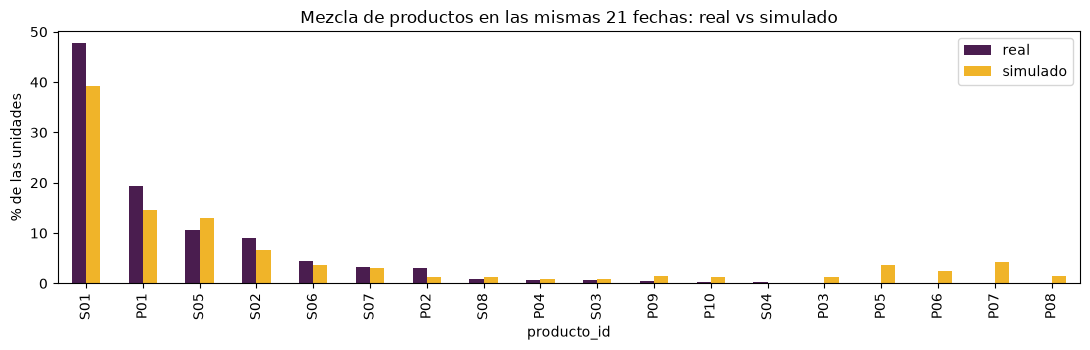

Correlación de la mezcla por producto (real vs simulado): 0.984
Unidades en las mismas fechas: real 501 | simulado 573 | simulado sin los 5 modelos que solo están en catálogo: 499


In [4]:
fechas_reales = reales.fecha_operacion.dt.normalize().unique()
sim_mismas = diarias[diarias.fecha_operacion.isin(fechas_reales)]

def resumen(df, origen):
    return pd.Series({
        "origen": origen,
        "dias_con_registro": df.fecha_operacion.dt.normalize().nunique(),
        "unidades": int(df.cantidad.sum()),
        "monto_S/": round(df.monto_total.sum(), 2),
        "precio_promedio_por_unidad_S/": round(df.monto_total.sum() / df.cantidad.sum(), 2),
        "unidades_por_línea": round(df.cantidad.mean(), 2),
        "%_shorts": round(100 * df[df.producto_id.str.startswith("S")].cantidad.sum() / df.cantidad.sum(), 1),
        "%_pago_Yape": round(100 * (df.metodo_pago == "Yape").mean(), 1),
    })

escala = pd.DataFrame([resumen(reales, "real"), resumen(sim_mismas, "simulado")]).set_index("origen")
display(escala)

dias_habiles_reales = reales.fecha_operacion.dt.normalize().nunique()
venta_mensual_real = reales.monto_total.sum() / dias_habiles_reales * 26  # 26 días hábiles (tienda cerrada domingos)
ventas_mes_sim = diarias.groupby(diarias.fecha_operacion.dt.to_period("M")).monto_total.sum()
print(f"Venta mensual equivalente real (sep–oct 2026): S/ {venta_mensual_real:,.0f}")
print(f"Venta mensual simulada: mediana S/ {ventas_mes_sim.median():,.0f} (mín. S/ {ventas_mes_sim.min():,.0f}, máx. S/ {ventas_mes_sim.max():,.0f} en diciembre)")

mezcla = pd.concat({
    "real": reales.groupby("producto_id").cantidad.sum() / reales.cantidad.sum(),
    "simulado": sim_mismas.groupby("producto_id").cantidad.sum() / sim_mismas.cantidad.sum(),
}, axis=1).fillna(0).sort_values("real", ascending=False)
ax = (mezcla * 100).plot.bar(figsize=(11, 3.6), color=["#4a1d4f", "#f0b429"])
ax.set_ylabel("% de las unidades"); ax.set_xlabel("producto_id")
ax.set_title("Mezcla de productos en las mismas 21 fechas: real vs simulado")
plt.tight_layout(); plt.savefig(FIGURAS / "mezcla_real_vs_simulado.png", dpi=130); plt.show()
print("Correlación de la mezcla por producto (real vs simulado):", round(mezcla.real.corr(mezcla.simulado), 3))
solo_catalogo = catalogo.loc[catalogo.fuente_producto == "Solo catálogo", "producto_id"]
sim_comparable = sim_mismas[~sim_mismas.producto_id.isin(solo_catalogo)]
print(f"Unidades en las mismas fechas: real {reales.cantidad.sum()} | simulado {sim_mismas.cantidad.sum()} "
      f"| simulado sin los {len(solo_catalogo)} modelos que solo están en catálogo: {sim_comparable.cantidad.sum()}")

**Conclusión de coherencia.**
- **Escala:** en las mismas 21 fechas, lo simulado suma 573 unidades frente a 501 reales. La diferencia corresponde a los 5 modelos que **solo están en el catálogo** (P03, P05–P08) y no aparecen en el cuaderno; sin ellos, lo simulado suma 499 unidades, prácticamente igual que lo real. Por la misma razón, la venta mensual simulada (mediana ≈ S/ 27.8 mil) es algo mayor que la equivalente real (≈ S/ 20.1 mil), con el pico de diciembre por Navidad.
- **Distribuciones por origen:** la mezcla de productos coincide (correlación 0.98), el precio promedio por unidad es similar (S/ 32.4 real vs S/ 34.4 simulado) y se mantienen el predominio de shorts y el uso de Yape.
- **Diferencia explicada:** en el cuaderno real cada fila resume la venta de un producto (≈ 6 unidades por fila), mientras que lo simulado se registra como boletas con 1–3 líneas, como las captura el MVP. Por eso «unidades por línea» no es comparable; sí lo son los totales, la mezcla y los precios.

## 4. Análisis exploratorio (EDA)

Estadísticos del target (unidades vendidas por SKU y semana):


,count,mean,std,min,25%,50%,75%,90%,99%,max
unidades_vendidas,4228.0,2.55,6.53,0.0,0.0,1.0,2.0,6.0,35.73,103.0


Semanas en cero: 47.2 % | semanas con quiebre de stock: 11.0 %
Demanda no atendida por falta de stock: 15.7 % (diagnóstico APF1: 15 %)


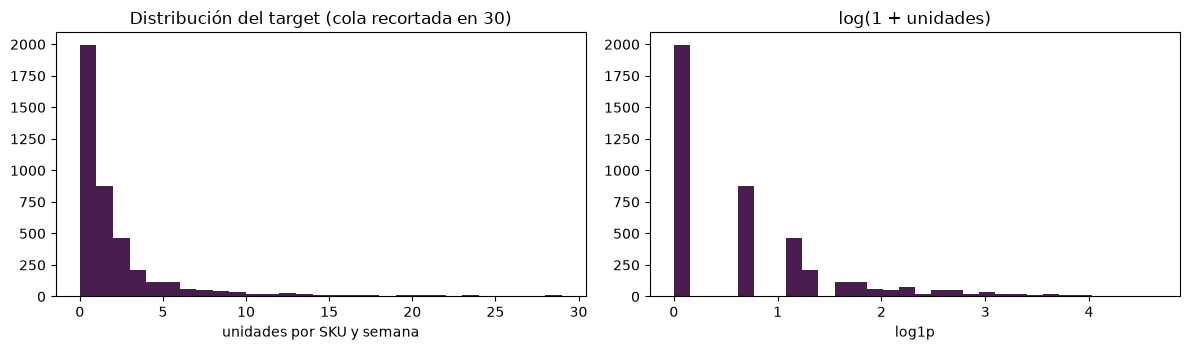

In [5]:
y = semanal.unidades_vendidas
print("Estadísticos del target (unidades vendidas por SKU y semana):")
display(y.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_frame().T)
print(f"Semanas en cero: {100 * (y == 0).mean():.1f} % | semanas con quiebre de stock: {100 * semanal.quiebre_stock.mean():.1f} %")
print(f"Demanda no atendida por falta de stock: {100 * semanal.demanda_no_atendida.sum() / semanal.demanda_real.sum():.1f} % (diagnóstico APF1: 15 %)")

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6))
ejes[0].hist(y, bins=range(0, 30), color="#4a1d4f")
ejes[0].set_title("Distribución del target (cola recortada en 30)"); ejes[0].set_xlabel("unidades por SKU y semana")
ejes[1].hist(np.log1p(y), bins=30, color="#4a1d4f")
ejes[1].set_title("log(1 + unidades)"); ejes[1].set_xlabel("log1p")
plt.tight_layout(); plt.savefig(FIGURAS / "distribucion_target.png", dpi=130); plt.show()

**Implicancia.** El target es un **conteo asimétrico** con muchas semanas bajas y algunas muy altas (pedidos mayoristas, Navidad). Por eso se reporta MAE (robusto) además de RMSE, y en boosting se prueba la pérdida **Poisson**, adecuada para conteos.

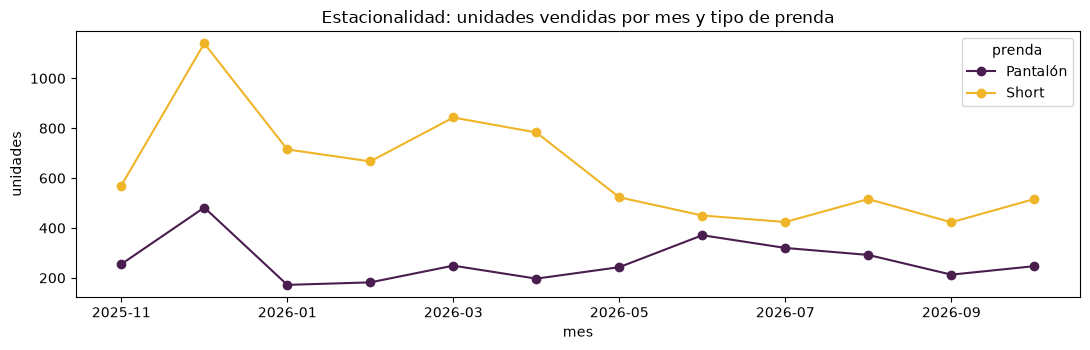

% de pantalones en las unidades por mes: {'2025-11': 30.9, '2025-12': 29.7, '2026-01': 19.4, '2026-02': 21.4, '2026-03': 22.8, '2026-04': 20.1, '2026-05': 31.7, '2026-06': 45.2, '2026-07': 43.0, '2026-08': 36.1, '2026-09': 33.5, '2026-10': 32.4}


In [6]:
mensual = semanal.groupby([semanal.periodo_semana.dt.to_period("M"), "prenda"]).unidades_vendidas.sum().unstack()
mensual.index = mensual.index.astype(str)  # etiquetas AAAA-MM
ax = mensual.plot(figsize=(11, 3.6), marker="o", color=["#4a1d4f", "#f0b429"])
ax.set_title("Estacionalidad: unidades vendidas por mes y tipo de prenda"); ax.set_ylabel("unidades"); ax.set_xlabel("mes")
plt.tight_layout(); plt.savefig(FIGURAS / "estacionalidad.png", dpi=130); plt.show()

participacion = (mensual["Pantalón"] / mensual.sum(axis=1) * 100).round(1)
print("% de pantalones en las unidades por mes:", participacion.to_dict())

**Relación plausible 1 — estacionalidad de Lima.** Los shorts suben en verano (dic–mar) y caen en invierno; los pantalones ganan participación de junio a agosto y ambos se disparan en diciembre por Navidad. **Implicancia:** el modelo necesita variables de calendario (semana del año en forma cíclica y temporada) y no basta con repetir la semana anterior.

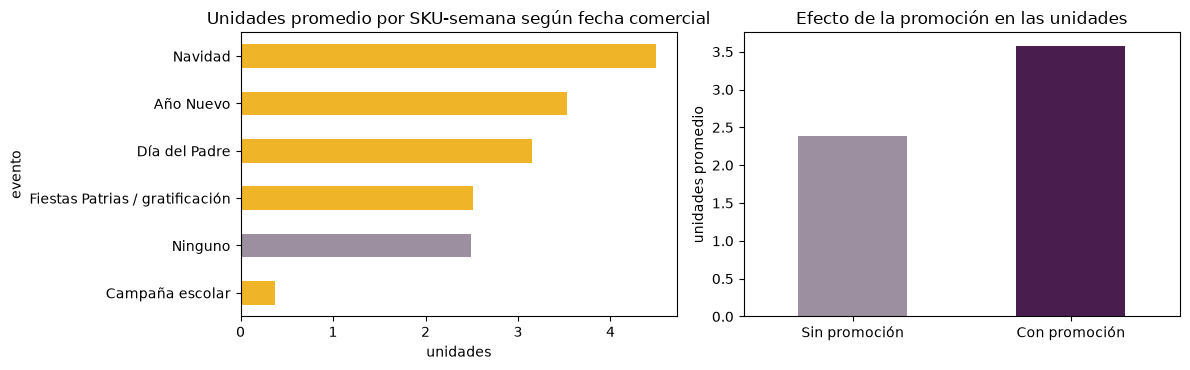

{'Campaña escolar': 0.38, 'Ninguno': 2.49, 'Fiestas Patrias / gratificación': 2.52, 'Día del Padre': 3.15, 'Año Nuevo': 3.53, 'Navidad': 4.49}
Con promoción se vende 1.50 veces lo que sin promoción.


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
por_evento = semanal.groupby("evento").unidades_vendidas.mean().sort_values()
por_evento.plot.barh(ax=ejes[0], color=["#f0b429" if e != "Ninguno" else "#9b8fa0" for e in por_evento.index])
ejes[0].set_title("Unidades promedio por SKU-semana según fecha comercial"); ejes[0].set_xlabel("unidades")
por_promo = semanal.groupby("en_promocion").unidades_vendidas.mean()
por_promo.index = ["Sin promoción", "Con promoción"]
por_promo.plot.bar(ax=ejes[1], color=["#9b8fa0", "#4a1d4f"], rot=0)
ejes[1].set_title("Efecto de la promoción en las unidades"); ejes[1].set_ylabel("unidades promedio")
plt.tight_layout(); plt.savefig(FIGURAS / "eventos_y_promociones.png", dpi=130); plt.show()
print(por_evento.round(2).to_dict())
print(f"Con promoción se vende {por_promo.iloc[1] / por_promo.iloc[0]:.2f} veces lo que sin promoción.")

**Relación plausible 2 — fechas comerciales y promociones.** Navidad, Fiestas Patrias, campaña escolar y Día del Padre elevan las ventas, y las semanas con descuento venden más que las semanas sin promoción. **Implicancia:** `evento`, `descuento` y `en_promocion` son variables que el negocio conoce **antes** de la semana y pueden usarse sin fuga.

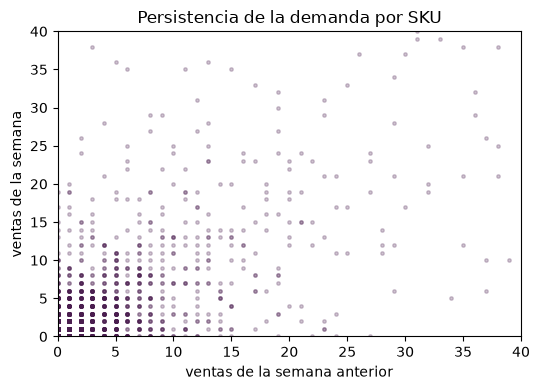

Correlación con la semana anterior: 0.692


In [8]:
orden = semanal.sort_values(["SKU", "periodo_semana"]).copy()
orden["venta_semana_anterior"] = orden.groupby("SKU").unidades_vendidas.shift(1)
validas = orden.dropna(subset=["venta_semana_anterior"])
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(validas.venta_semana_anterior, validas.unidades_vendidas, s=6, alpha=0.25, color="#4a1d4f")
ax.set_xlim(0, 40); ax.set_ylim(0, 40)
ax.set_xlabel("ventas de la semana anterior"); ax.set_ylabel("ventas de la semana")
ax.set_title("Persistencia de la demanda por SKU")
plt.tight_layout(); plt.savefig(FIGURAS / "persistencia.png", dpi=130); plt.show()
print("Correlación con la semana anterior:", round(validas.venta_semana_anterior.corr(validas.unidades_vendidas), 3))

**Señal ni nula ni perfecta.** Las ventas de una semana se relacionan con las de la semana anterior (correlación moderada), pero con mucha dispersión: hay señal aprovechable y también ruido real de la demanda. No se espera un R² cercano a 1; si apareciera, sería señal de fuga.

## 5. Limpieza y transformación
**Criterios explícitos**
- **Nulos y duplicados:** no hay (sección 3.1). No se elimina ni imputa nada a ciegas.
- **Outliers:** las semanas muy altas son **pedidos mayoristas** reales del negocio (como los 64 pantalones del 20-oct-2026) y Navidad. **Se conservan** porque representan demanda real; se mitiga su peso con MAE y con la pérdida Poisson.
- **Quiebres de stock:** `unidades_vendidas` está limitada por el stock (venta censurada). Siguiendo el contrato («la ausencia de ventas no es demanda cero si no hubo stock») se agrega `quiebre_lag1` para que el modelo sepa si la semana anterior se vendió menos por falta de stock.
- **Primeras 4 semanas de cada SKU:** no tienen historial para calcular rezagos; se excluyen del modelado (no se inventan valores).

**Variables derivadas (ingeniería de características)**
- `venta_lag1`, `venta_lag2`, `venta_lag4`: ventas pasadas del mismo SKU.
- `media_4`: promedio de las 4 semanas anteriores = **la regla que hoy usa el dueño** para reponer.
- `quiebre_lag1`: hubo quiebre la semana anterior.
- `semana_sen`, `semana_cos`: semana del año en forma cíclica (la semana 52 está cerca de la 1).
- `es_evento`: la semana tiene fecha comercial.

**Variables excluidas por fuga de información:** `demanda_real`, `demanda_no_atendida`, `quiebre_stock`, `stock_final` y `unidades_recibidas` **de la misma semana** (solo se conocen al cierre). También `stock_disponible`: el objetivo es estimar la demanda para decidir la reposición, no copiar el stock.

In [9]:
def crear_variables(df):
    d = df.sort_values(["SKU", "periodo_semana"]).copy()
    grupo = d.groupby("SKU").unidades_vendidas
    d["venta_lag1"] = grupo.shift(1)
    d["venta_lag2"] = grupo.shift(2)
    d["venta_lag4"] = grupo.shift(4)
    d["media_4"] = grupo.transform(lambda s: s.shift(1).rolling(4, min_periods=4).mean())
    d["quiebre_lag1"] = d.groupby("SKU").quiebre_stock.shift(1)
    d["semana_sen"] = np.sin(2 * np.pi * d.semana_iso / 52)
    d["semana_cos"] = np.cos(2 * np.pi * d.semana_iso / 52)
    d["es_evento"] = (d.evento != "Ninguno").astype(int)
    return d

VAR_CATEGORICAS = ["producto_id", "talla", "prenda", "modelo", "segmento", "temporada", "evento"]
VAR_NUMERICAS = [
    "venta_lag1", "venta_lag2", "venta_lag4", "media_4", "quiebre_lag1",
    "precio_unitario", "descuento", "en_promocion", "es_evento",
    "semanas_desde_lanzamiento", "semana_sen", "semana_cos", "tiempo_de_entrega",
]
VARIABLES = VAR_CATEGORICAS + VAR_NUMERICAS
OBJETIVO = "unidades_vendidas"

datos = crear_variables(semanal)
antes = len(datos)
datos = datos.dropna(subset=["venta_lag4", "media_4", "quiebre_lag1"]).reset_index(drop=True)
datos["quiebre_lag1"] = datos.quiebre_lag1.astype(int)
print(f"Filas: {antes} → {len(datos)} (se excluyen {antes - len(datos)} semanas iniciales sin historial)")
print("Nulos en variables del modelo:", int(datos[VARIABLES].isna().sum().sum()))
datos[["SKU", "periodo_semana"] + VARIABLES[:2] + VAR_NUMERICAS[:5] + [OBJETIVO]].head()

Filas: 4228 → 3888 (se excluyen 340 semanas iniciales sin historial)
Nulos en variables del modelo: 0


,SKU,periodo_semana,producto_id,talla,venta_lag1,venta_lag2,venta_lag4,media_4,quiebre_lag1,unidades_vendidas
0,P01-28,2025-12-01,P01,28,8.0,5.0,9.0,7.5,0,7
1,P01-28,2025-12-08,P01,28,7.0,8.0,8.0,7.0,0,16
2,P01-28,2025-12-15,P01,28,16.0,7.0,5.0,9.0,1,17
3,P01-28,2025-12-22,P01,28,17.0,16.0,8.0,12.0,1,8
4,P01-28,2025-12-29,P01,28,8.0,17.0,7.0,12.0,0,14


## 6. Partición cronológica y prevención de fuga
Como pide el Contrato de Datos de APF2: **70 % de las semanas más antiguas para entrenamiento, 15 % para validación y 15 % más reciente para prueba**, sin mezclar filas al azar. El preprocesamiento (escalado y one-hot) vive dentro de un `Pipeline`, así que **solo se ajusta con datos de entrenamiento**.

In [10]:
semanas = np.sort(datos.periodo_semana.unique())
n = len(semanas)
n_ent, n_val = round(0.70 * n), round(0.15 * n)
sem_ent, sem_val, sem_prueba = semanas[:n_ent], semanas[n_ent:n_ent + n_val], semanas[n_ent + n_val:]

entrenamiento = datos[datos.periodo_semana.isin(sem_ent)]
validacion = datos[datos.periodo_semana.isin(sem_val)]
prueba = datos[datos.periodo_semana.isin(sem_prueba)]
for nombre, parte, sems in [("Entrenamiento", entrenamiento, sem_ent), ("Validación", validacion, sem_val), ("Prueba", prueba, sem_prueba)]:
    print(f"{nombre:13s}: {len(parte):5d} filas | {len(sems):2d} semanas | {pd.Timestamp(sems[0]).date()} a {(pd.Timestamp(sems[-1]) + pd.Timedelta(days=6)).date()}")

X_ent, y_ent = entrenamiento[VARIABLES], entrenamiento[OBJETIVO]
X_val, y_val = validacion[VARIABLES], validacion[OBJETIVO]
X_prueba, y_prueba = prueba[VARIABLES], prueba[OBJETIVO]

# Validación cruzada temporal SOLO dentro del entrenamiento: ventana creciente,
# cada pliegue valida las 4 semanas siguientes (nunca usa el futuro para entrenar).
def pliegues_temporales(df, n_pliegues=4, semanas_validacion=4):
    sems = np.sort(df.periodo_semana.unique())
    posicion = df.periodo_semana.reset_index(drop=True)
    pliegues = []
    for k in range(n_pliegues, 0, -1):
        corte = len(sems) - k * semanas_validacion
        ent = np.where(posicion.isin(sems[:corte]))[0]
        val = np.where(posicion.isin(sems[corte:corte + semanas_validacion]))[0]
        pliegues.append((ent, val))
    return pliegues

PLIEGUES = pliegues_temporales(entrenamiento)
print("Pliegues de validación cruzada temporal:", [(len(a), len(b)) for a, b in PLIEGUES])

Entrenamiento:  2754 filas | 34 semanas | 2025-12-01 a 2026-07-26
Validación   :   567 filas |  7 semanas | 2026-07-27 a 2026-09-13
Prueba       :   567 filas |  7 semanas | 2026-09-14 a 2026-11-01
Pliegues de validación cruzada temporal: [(1458, 324), (1782, 324), (2106, 324), (2430, 324)]


## 7. Modelado
### 7.1 Líneas base (obligatorias)
1. **Pronóstico ingenuo:** las ventas de la semana anterior (`venta_lag1`). Es la comparación que exige la consigna en series temporales.
2. **Regla actual del dueño:** el promedio de las últimas 4 semanas (`media_4`). Es lo que hoy usa la MiPYME para decidir la reposición.
3. **DummyRegressor:** la media del entrenamiento (referencia mínima).

### 7.2 Modelos de la Unidad 3 (regresión)
| Modelo | Por qué se eligió | Control de sobreajuste |
|---|---|---|
| **Ridge** (regresión lineal regularizada) | Simple, rápida e interpretable por coeficientes; requiere escalado (se aplica `StandardScaler`). | Regularización L2 (`alpha`). |
| **Árbol de decisión** | Captura reglas no lineales y se puede explicar al dueño como reglas «si… entonces». | `max_depth` y `min_samples_leaf`. |
| **Gradient Boosting** (`HistGradientBoostingRegressor`) | Suele ser el más preciso en datos tabulares; admite pérdida Poisson para conteos. | Profundidad, tasa de aprendizaje, número de iteraciones y regularización L2. |

Los tres usan **la misma partición y el mismo preprocesamiento**. Los hiperparámetros se buscan con `GridSearchCV` y **validación cruzada temporal solo sobre entrenamiento**; el modelo se elige con el conjunto de **validación**, y la **prueba se usa una sola vez al final**.

In [11]:
def preprocesador():
    return ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), VAR_CATEGORICAS),
        ("numericas", StandardScaler(), VAR_NUMERICAS),
    ])

def wape(real, pred):
    return float(np.abs(real - pred).sum() / np.abs(real).sum())

def metricas(real, pred):
    real, pred = np.asarray(real, dtype=float), np.clip(np.asarray(pred, dtype=float), 0, None)
    return {
        "MAE": mean_absolute_error(real, pred),
        "RMSE": math.sqrt(mean_squared_error(real, pred)),
        "R2": r2_score(real, pred),
        "WAPE_%": 100 * wape(real, pred),
        "sesgo": float((pred - real).mean()),
    }

candidatos = {
    "Ridge": (
        Ridge(),
        {"modelo__alpha": [0.1, 1, 10, 100]},
    ),
    "Árbol de decisión": (
        DecisionTreeRegressor(random_state=SEMILLA),
        {"modelo__max_depth": [4, 6, 8, 12], "modelo__min_samples_leaf": [5, 10, 20]},
    ),
    "Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=SEMILLA),
        {
            "modelo__loss": ["squared_error", "poisson"],
            "modelo__learning_rate": [0.05, 0.1],
            "modelo__max_depth": [3, 6],
            "modelo__max_iter": [200, 400],
            "modelo__l2_regularization": [0.0, 1.0],
        },
    ),
}

busquedas = {}
for nombre, (estimador, grilla) in candidatos.items():
    inicio = time.perf_counter()
    busqueda = GridSearchCV(
        Pipeline([("prep", preprocesador()), ("modelo", estimador)]),
        grilla,
        cv=PLIEGUES,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
        return_train_score=True,
    )
    busqueda.fit(X_ent.reset_index(drop=True), y_ent.reset_index(drop=True))
    busquedas[nombre] = busqueda
    print(f"{nombre:18s} mejores parámetros: {busqueda.best_params_} | MAE CV: {-busqueda.best_score_:.3f} | {time.perf_counter() - inicio:.1f} s")

Ridge              mejores parámetros: {'modelo__alpha': 100} | MAE CV: 1.711 | 1.3 s
Árbol de decisión  mejores parámetros: {'modelo__max_depth': 4, 'modelo__min_samples_leaf': 10} | MAE CV: 1.586 | 0.2 s


Gradient Boosting  mejores parámetros: {'modelo__l2_regularization': 0.0, 'modelo__learning_rate': 0.05, 'modelo__loss': 'poisson', 'modelo__max_depth': 3, 'modelo__max_iter': 400} | MAE CV: 1.492 | 4.1 s


### 7.3 Selección con el conjunto de validación y control de sobreajuste

In [12]:
filas = []
predicciones_val = {
    "Ingenuo (semana anterior)": X_val.venta_lag1.values,
    "Regla del dueño (promedio 4 semanas)": X_val.media_4.values,
}
dummy = Pipeline([("prep", preprocesador()), ("modelo", DummyRegressor(strategy="mean"))]).fit(X_ent, y_ent)
predicciones_val["Dummy (media)"] = dummy.predict(X_val)
for nombre, busqueda in busquedas.items():
    predicciones_val[nombre] = busqueda.best_estimator_.predict(X_val)

for nombre, pred in predicciones_val.items():
    fila = {"modelo": nombre, **{f"{k}_val": v for k, v in metricas(y_val, pred).items()}}
    if nombre in busquedas:
        fila["MAE_entrenamiento"] = metricas(y_ent, busquedas[nombre].best_estimator_.predict(X_ent))["MAE"]
    filas.append(fila)

tabla_validacion = pd.DataFrame(filas).set_index("modelo").round(3)
display(tabla_validacion)

modelos_ml = tabla_validacion.loc[list(busquedas)]
ELEGIDO = modelos_ml.MAE_val.idxmin()
print(f"Modelo elegido por menor MAE en validación: {ELEGIDO}")
brecha = modelos_ml.MAE_val - modelos_ml.MAE_entrenamiento
print("Brecha validación − entrenamiento (MAE), menor es mejor:", brecha.round(3).to_dict())

,MAE_val,RMSE_val,R2_val,WAPE_%_val,sesgo_val,MAE_entrenamiento
modelo,,,,,,
Ingenuo (semana anterior),1.744,3.904,0.344,87.445,0.150,NaN
Regla del dueño (promedio 4 semanas),1.467,3.226,0.552,73.541,0.198,NaN
Dummy (media),2.893,4.880,-0.025,145.028,0.765,NaN
Ridge,1.465,3.184,0.564,73.425,0.131,1.732
Árbol de decisión,1.495,3.247,0.546,74.952,0.226,1.617
Gradient Boosting,1.495,3.307,0.529,74.957,0.241,1.267


Modelo elegido por menor MAE en validación: Ridge
Brecha validación − entrenamiento (MAE), menor es mejor: {'Ridge': -0.267, 'Árbol de decisión': -0.122, 'Gradient Boosting': 0.228}


**Cómo se lee.** Un modelo sobreajustado tiene MAE de entrenamiento mucho menor que en validación. La regularización (`alpha`, profundidad máxima, hojas mínimas y L2) se eligió por validación cruzada temporal para limitar esa brecha. El modelo se elige por **menor MAE en validación** (error en unidades que entiende el dueño) y se revisa que también mejore el WAPE y que su sesgo no sea fuertemente negativo (subestimar provoca quiebres).

## 8. Evaluación final en el conjunto de prueba (se usa una sola vez)
Cada modelo se reentrena con **entrenamiento + validación** usando los hiperparámetros ya elegidos y se evalúa una única vez sobre las últimas semanas. La elección del modelo **ya quedó fijada** en la sección 7.3.

In [13]:
X_ent_val = pd.concat([X_ent, X_val])
y_ent_val = pd.concat([y_ent, y_val])

finales = {}
for nombre, busqueda in busquedas.items():
    finales[nombre] = Pipeline([("prep", preprocesador()), ("modelo", busqueda.best_estimator_.named_steps["modelo"])]).fit(X_ent_val, y_ent_val)
dummy_final = Pipeline([("prep", preprocesador()), ("modelo", DummyRegressor(strategy="mean"))]).fit(X_ent_val, y_ent_val)

predicciones_prueba = {
    "Ingenuo (semana anterior)": X_prueba.venta_lag1.values,
    "Regla del dueño (promedio 4 semanas)": X_prueba.media_4.values,
    "Dummy (media)": dummy_final.predict(X_prueba),
    **{nombre: modelo.predict(X_prueba) for nombre, modelo in finales.items()},
}
precio = prueba.precio_unitario.values
filas = []
for nombre, pred in predicciones_prueba.items():
    pred = np.clip(pred, 0, None)
    faltante = np.clip(y_prueba.values - pred, 0, None)   # unidades que el pronóstico se quedó corto
    filas.append({
        "modelo": nombre,
        **metricas(y_prueba, pred),
        "unidades_subestimadas": faltante.sum(),
        "S/_subestimados": (faltante * precio).sum(),
    })
tabla_prueba = pd.DataFrame(filas).set_index("modelo").round(2)
tabla_prueba["seleccionado"] = np.where(tabla_prueba.index == ELEGIDO, "✔", "")
display(tabla_prueba)

ref = tabla_prueba.loc["Regla del dueño (promedio 4 semanas)"]
ing = tabla_prueba.loc["Ingenuo (semana anterior)"]
eleg = tabla_prueba.loc[ELEGIDO]
print(f"{ELEGIDO}: MAE {eleg.MAE:.2f} vs regla del dueño {ref.MAE:.2f} ({100 * (1 - eleg.MAE / ref.MAE):.1f} % menos error) "
      f"y vs ingenuo {ing.MAE:.2f} ({100 * (1 - eleg.MAE / ing.MAE):.1f} % menos error).")
print(f"WAPE: {eleg['WAPE_%']:.1f} % vs regla del dueño {ref['WAPE_%']:.1f} %.")
tabla_prueba.to_csv(FIGURAS / "tabla_metricas_prueba.csv")

,MAE,RMSE,R2,WAPE_%,sesgo,unidades_subestimadas,S/_subestimados,seleccionado
modelo,,,,,,,,
Ingenuo (semana anterior),2.06,4.76,0.21,94.57,-0.06,600.00,21181.62,
Regla del dueño (promedio 4 semanas),1.51,3.23,0.63,69.45,-0.16,474.25,16427.40,
Dummy (media),2.99,5.37,-0.01,137.07,0.45,718.55,22691.18,
Ridge,1.40,3.13,0.66,64.18,-0.28,477.04,17035.84,✔
Árbol de decisión,1.63,3.47,0.58,74.68,-0.11,493.18,16976.24,
Gradient Boosting,1.47,3.11,0.66,67.68,-0.30,503.13,17338.01,


Ridge: MAE 1.40 vs regla del dueño 1.51 (7.3 % menos error) y vs ingenuo 2.06 (32.0 % menos error).
WAPE: 64.2 % vs regla del dueño 69.5 %.


### Interpretación de negocio (6.2)
- **Precisión:** Ridge se equivoca en promedio **1.40 unidades por SKU y semana**, frente a 1.51 de la regla del dueño (**7 % menos error**) y 2.06 del pronóstico ingenuo (**32 % menos**). El WAPE baja de 69 % a 64 %. El WAPE es alto porque casi la mitad de las semanas por talla tienen 0–1 ventas: a ese nivel la demanda es muy irregular y ningún método la acierta exacta.
- **Por qué Ridge y no boosting:** en validación los tres modelos quedaron muy cerca. Se eligió Ridge porque tuvo el menor MAE en validación, se sobreajusta menos (su error en entrenamiento no es menor que en validación), pesa 7 KB, predice en ~1.5 ms y sus coeficientes se explican fácilmente al dueño. Gradient Boosting logra un RMSE parecido, pero es más complejo sin una ganancia clara.
- **Meta del Paso 1:** el modelo **mejora el error de pronóstico**, pero por sí solo **no demuestra todavía la reducción del 15 % de pedidos no atendidos**. Las unidades subestimadas son similares a las de la regla del dueño (≈ 477 vs 474) y su sesgo es levemente negativo. Para reducir quiebres, la predicción se combina con el **stock de seguridad y el tiempo de entrega** en la reposición sugerida (`predecir.py`), y su efecto debe medirse en el piloto.
- **Qué habilita:** una sugerencia semanal y automática de cuánto reponer por talla, en lugar de revisar el cuaderno. Reemplaza el cálculo manual del promedio y anticipa temporadas, campañas y promociones que el promedio de 4 semanas detecta tarde.
- **Qué no puede hacer:** predecir pedidos mayoristas ni demanda de productos sin historial, ni garantizar cero quiebres. Los resultados son **indicativos** porque se entrenó con datos simulados.

### 8.1 Análisis de errores

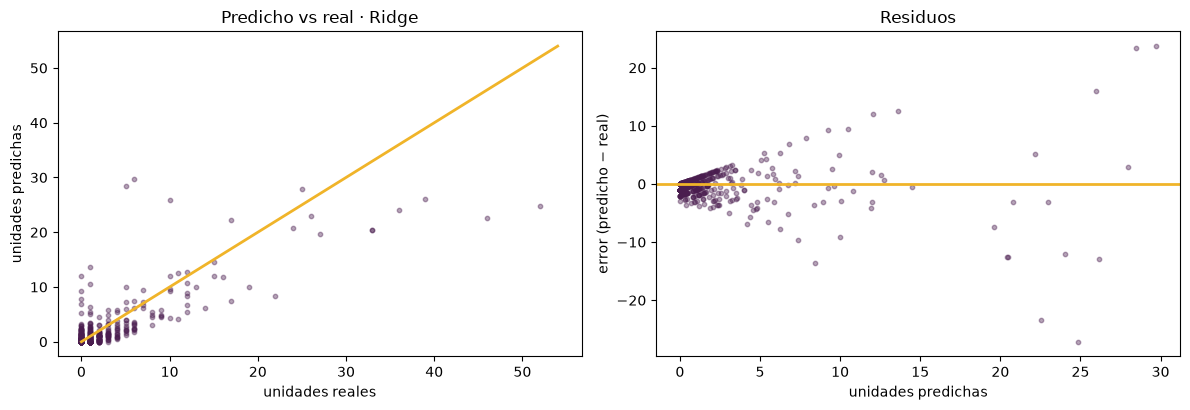

,SKU,periodo_semana,nombre_producto,unidades_vendidas,prediccion,error,hipótesis
2538,S01-30,2026-09-21,Short papertash,52,24.86,-27.14,hubo quiebre: la venta quedó limitada por el s...
2539,S01-30,2026-09-28,Short papertash,6,29.73,23.73,variación propia de la demanda
2589,S01-32,2026-10-12,Short papertash,46,22.51,-23.49,variación propia de la demanda
2590,S01-32,2026-10-19,Short papertash,5,28.44,23.44,variación propia de la demanda
2543,S01-30,2026-10-26,Short papertash,10,25.98,15.98,variación propia de la demanda


In [14]:
modelo_final = finales[ELEGIDO]
analisis = prueba[["SKU", "periodo_semana", "nombre_producto", "evento", "en_promocion", "media_4", "quiebre_stock",
                   "demanda_real", "semanas_desde_lanzamiento", OBJETIVO]].copy()
analisis["prediccion"] = np.clip(modelo_final.predict(X_prueba), 0, None)
analisis["error"] = analisis.prediccion - analisis[OBJETIVO]

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
lim = max(analisis[OBJETIVO].max(), analisis.prediccion.max()) + 2
ejes[0].scatter(analisis[OBJETIVO], analisis.prediccion, s=10, alpha=0.4, color="#4a1d4f")
ejes[0].plot([0, lim], [0, lim], color="#f0b429", lw=2)
ejes[0].set_xlabel("unidades reales"); ejes[0].set_ylabel("unidades predichas"); ejes[0].set_title(f"Predicho vs real · {ELEGIDO}")
ejes[1].scatter(analisis.prediccion, analisis.error, s=10, alpha=0.4, color="#4a1d4f")
ejes[1].axhline(0, color="#f0b429", lw=2)
ejes[1].set_xlabel("unidades predichas"); ejes[1].set_ylabel("error (predicho − real)"); ejes[1].set_title("Residuos")
plt.tight_layout(); plt.savefig(FIGURAS / "errores_modelo.png", dpi=130); plt.show()

def hipotesis(f):
    motivos = []
    if f[OBJETIVO] > 3 * max(f.media_4, 1):
        motivos.append("venta muy superior a su historial: probable pedido mayorista")
    if f.quiebre_stock:
        motivos.append("hubo quiebre: la venta quedó limitada por el stock")
    if f.semanas_desde_lanzamiento < 12:
        motivos.append("producto recién lanzado, con poco historial")
    if f.evento != "Ninguno":
        motivos.append(f"semana con fecha comercial ({f.evento})")
    if f.en_promocion:
        motivos.append("semana con promoción")
    return "; ".join(motivos) or "variación propia de la demanda"

peores = analisis.reindex(analisis.error.abs().sort_values(ascending=False).index).head(5).copy()
peores["hipótesis"] = peores.apply(hipotesis, axis=1)
display(peores[["SKU", "periodo_semana", "nombre_producto", OBJETIVO, "prediccion", "error", "hipótesis"]].round({"prediccion": 2, "error": 2}))

**Lectura de los casos de falla.** Los errores grandes se concentran en **pedidos mayoristas** (picos que no se anticipan con el historial) y en semanas con **quiebre de stock**, donde la venta real quedó limitada por la falta de producto. Ambos casos son esperables: el mayorista no se puede predecir con estas variables y en PROY se propone registrarlo como pedido aparte; en los quiebres, el modelo aprende de ventas censuradas, por lo que conviene registrar en el MVP la **demanda no atendida** (cliente que se fue sin talla).

In [15]:
# Diagnóstico solo posible con datos simulados: comparar contra la demanda real (incluye lo que no se pudo atender).
for nombre in ["Regla del dueño (promedio 4 semanas)", ELEGIDO]:
    pred = np.clip(predicciones_prueba[nombre], 0, None)
    corta = np.clip(prueba.demanda_real.values - pred, 0, None).sum()
    print(f"{nombre:38s} → la demanda real superó el pronóstico en {corta:,.0f} unidades en el periodo de prueba")

Regla del dueño (promedio 4 semanas)   → la demanda real superó el pronóstico en 692 unidades en el periodo de prueba
Ridge                                  → la demanda real superó el pronóstico en 699 unidades en el periodo de prueba


### 8.2 Importancia de variables

,variable,aumento_MAE,desviación
0,media_4,0.2878,0.0158
1,venta_lag2,0.2137,0.0172
2,precio_unitario,0.1678,0.0159
3,tiempo_de_entrega,0.1414,0.0193
4,producto_id,0.1358,0.0100
5,modelo,0.1334,0.0124
6,semanas_desde_lanzamiento,0.0939,0.0068
7,en_promocion,0.0534,0.0076
8,talla,0.0500,0.0124
9,segmento,0.0439,0.0069


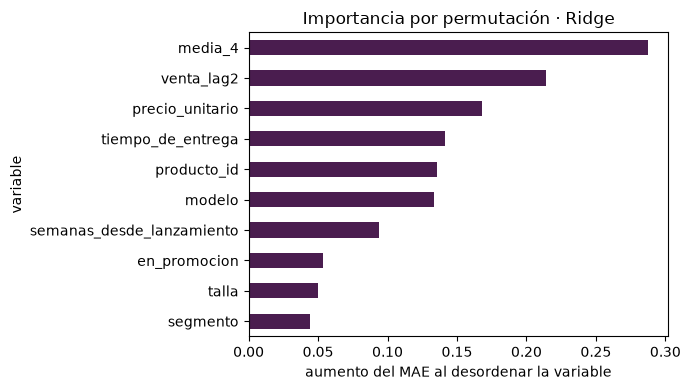

In [16]:
importancia = permutation_importance(
    modelo_final, X_prueba, y_prueba, n_repeats=10, random_state=SEMILLA, scoring="neg_mean_absolute_error", n_jobs=-1
)
tabla_importancia = (
    pd.DataFrame({"variable": VARIABLES, "aumento_MAE": importancia.importances_mean, "desviación": importancia.importances_std})
    .sort_values("aumento_MAE", ascending=False).reset_index(drop=True)
)
display(tabla_importancia.round(4).head(12))
ax = tabla_importancia.head(10).iloc[::-1].plot.barh(x="variable", y="aumento_MAE", legend=False, figsize=(7, 4), color="#4a1d4f")
ax.set_xlabel("aumento del MAE al desordenar la variable"); ax.set_title(f"Importancia por permutación · {ELEGIDO}")
plt.tight_layout(); plt.savefig(FIGURAS / "importancia_variables.png", dpi=130); plt.show()

**Qué acción sugiere cada hallazgo**
- **Historial reciente (`media_4`, rezagos):** registrar **todas** las ventas en el MVP es lo que más mejora el pronóstico; si una venta no se registra, la predicción de la semana siguiente empeora.
- **Producto y talla:** cada talla tiene su propio ritmo; la reposición debe decidirse por SKU, no por modelo completo.
- **Calendario y fechas comerciales:** el modelo anticipa temporadas y campañas que la regla del dueño (promedio de 4 semanas) solo detecta tarde.
- **Precio y promoción:** cuando se lanza una promoción, hay que reponer antes porque la demanda sube.

## 9. Viabilidad de despliegue
El MVP corre en Cloudflare Workers (JavaScript, 10 ms de CPU por solicitud en el plan gratuito), que no ejecuta scikit-learn. Por eso el modelo se sirve como **servicio Python aparte** (`predecir.py`, función o endpoint HTTP) que el MVP consulta. Se mide el tamaño del archivo y el tiempo de predicción.

In [17]:
artefacto = {
    "modelo": modelo_final,
    "nombre_modelo": ELEGIDO,
    "variables": VARIABLES,
    "catalogo": {
        r.producto_id: {
            "prenda": r.prenda, "modelo": r.modelo, "segmento": r.segmento,
            "tallas": [t.strip() for t in r.tallas.split(",")],
            "fecha_lanzamiento": r.fecha_lanzamiento, "tiempo_entrega_semanas": int(r.tiempo_entrega_semanas),
        }
        for r in catalogo.itertuples()
    },
    "metricas_prueba": {k: round(float(v), 4) for k, v in tabla_prueba.loc[ELEGIDO, ["MAE", "RMSE", "R2", "WAPE_%"]].items()},
    "entrenado_hasta": str((pd.Timestamp(sem_val[-1]) + pd.Timedelta(days=6)).date()),
    "versiones": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
ruta_modelo = MODELO / "modelo_demanda.joblib"
joblib.dump(artefacto, ruta_modelo)
print(f"Modelo exportado: {ruta_modelo} ({ruta_modelo.stat().st_size / 1024:.0f} KB)")

inicio = time.perf_counter()
for _ in range(200):
    modelo_final.predict(X_prueba.iloc[[0]])
print(f"Tiempo medio de predicción de un registro: {(time.perf_counter() - inicio) / 200 * 1000:.1f} ms")

Modelo exportado: modelo/modelo_demanda.joblib (7 KB)


Tiempo medio de predicción de un registro: 1.5 ms


## 10. Integración con el MVP: contrato y llamada real al modelo exportado
**Flujo:** el MVP registra ventas confirmadas (`ventas`, `lineas_venta`) → se agregan por SKU y semana → `predecir.py` arma las variables → el modelo predice → la pantalla de **Inventario/Inicio** muestra «unidades estimadas» y «reponer N unidades».

**Esquema de entrada (campos que el MVP ya captura)**
```json
{
  "producto_id": "S01",              // productos.id homologado
  "talla": "30",                     // combinaciones (talla)
  "semana": "2026-11-02",            // lunes de la semana a pronosticar
  "precio_lista": 30,                // productos.precio
  "descuento": 0.0,                  // promoción planificada
  "ventas_ultimas_4_semanas": [5, 7, 4, 6],   // suma de lineas_venta.cantidad por semana (antigua → reciente)
  "hubo_quiebre_semana_anterior": false,      // existencias llegaron a 0 (movimientos_inventario)
  "stock_actual": 3,                 // productos.existencias / combinaciones.existencias
  "tiempo_entrega_semanas": 1,       // parámetro del negocio
  "stock_seguridad": 2               // parámetro del negocio
}
```
**Esquema de salida:** `unidades_estimadas`, `reposicion_sugerida` y `accion` («reponer» o «stock suficiente»). **Acción en la interfaz:** si `accion = reponer`, el MVP muestra una alerta en Inventario con la cantidad sugerida; la decisión final la toma el responsable del inventario.

In [18]:
# 1) Consistencia: predecir.py reconstruye las variables igual que el notebook para una fila real de prueba.
fila = prueba.iloc[0]
historial = (
    semanal[(semanal.SKU == fila.SKU) & (semanal.periodo_semana < fila.periodo_semana)]
    .sort_values("periodo_semana").unidades_vendidas.tail(4).tolist()
)
registro_prueba = {
    "producto_id": fila.producto_id, "talla": fila.talla, "semana": str(fila.periodo_semana.date()),
    "precio_lista": float(fila.precio_lista), "descuento": float(fila.descuento),
    "ventas_ultimas_4_semanas": historial, "hubo_quiebre_semana_anterior": bool(fila.quiebre_lag1),
    "stock_actual": int(fila.stock_disponible), "tiempo_entrega_semanas": int(fila.tiempo_de_entrega),
    "stock_seguridad": int(fila.stock_de_seguridad),
}
respuesta = predecir.predecir(registro_prueba, ruta_modelo)
esperado = float(np.clip(modelo_final.predict(X_prueba.iloc[[0]]), 0, None)[0])
print("Predicción del notebook:", round(esperado, 2), "| predicción vía predecir.py:", respuesta["unidades_estimadas"])
assert abs(esperado - respuesta["unidades_estimadas"]) < 0.01, "predecir.py no reproduce las variables del notebook"

# 2) Registro NUEVO (semana posterior al dataset), con el esquema del MVP.
ultimas = semanal[semanal.SKU == "S02-30"].sort_values("periodo_semana").tail(4)
registro_nuevo = {
    "producto_id": "S02", "talla": "30", "semana": "2026-11-02",   # semana siguiente al dataset
    "precio_lista": 33, "descuento": 0.0,
    "ventas_ultimas_4_semanas": ultimas.unidades_vendidas.astype(int).tolist(),
    "hubo_quiebre_semana_anterior": bool(ultimas.quiebre_stock.iloc[-1]),
    "stock_actual": int(ultimas.stock_final.iloc[-1]), "tiempo_entrega_semanas": 2, "stock_seguridad": 2,
}
print("Entrada (JSON del MVP):", json.dumps(registro_nuevo, ensure_ascii=False))
with open("ejemplo_entrada.json", "w", encoding="utf-8") as archivo:
    json.dump(registro_nuevo, archivo, ensure_ascii=False, indent=2)
print(json.dumps(predecir.predecir(registro_nuevo, ruta_modelo), ensure_ascii=False, indent=2))

Predicción del notebook: 5.45 | predicción vía predecir.py: 5.45
Entrada (JSON del MVP): {"producto_id": "S02", "talla": "30", "semana": "2026-11-02", "precio_lista": 33, "descuento": 0.0, "ventas_ultimas_4_semanas": [0, 4, 1, 6], "hubo_quiebre_semana_anterior": false, "stock_actual": 0, "tiempo_entrega_semanas": 2, "stock_seguridad": 2}
{
  "sku": "S02-30",
  "semana": "2026-11-02",
  "evento": "Ninguno",
  "unidades_estimadas": 3.07,
  "unidades_estimadas_redondeadas": 3,
  "cobertura_semanas": 3,
  "reposicion_sugerida": 12,
  "accion": "reponer",
  "modelo": "Ridge",
  "mae_prueba": 1.4
}


**Estado de implementación.**
- **Hoy (APF3):** modelo entrenado, exportado y servido por `predecir.py` como función y como endpoint HTTP (`python predecir.py --servir 8000`, `POST /predecir`). El MVP ya captura todos los campos de entrada (ventas confirmadas por producto y talla, stock y movimientos).
- **Pendiente para PROY:** publicar el endpoint en un servicio gratuito con Python, agregar en el MVP la consulta semanal por SKU y mostrar la alerta de reposición en Inventario/Inicio, y registrar la demanda no atendida y los pedidos mayoristas para reentrenar con datos reales.

**Límite declarado.** El modelo se entrenó con datos **simulados** calibrados con 21 días reales: los resultados son **indicativos** y deben validarse con las ventas reales que el MVP capture durante el piloto antes de usarlos para decisiones de compra.

## 11. Resumen

In [19]:
print("Filas modeladas:", len(datos), "| Entrenamiento/validación/prueba (semanas):", len(sem_ent), len(sem_val), len(sem_prueba))
print("Modelo seleccionado:", ELEGIDO, "| parámetros:", busquedas[ELEGIDO].best_params_)
display(tabla_prueba[["MAE", "RMSE", "R2", "WAPE_%", "sesgo", "unidades_subestimadas", "seleccionado"]])

Filas modeladas: 3888 | Entrenamiento/validación/prueba (semanas): 34 7 7
Modelo seleccionado: Ridge | parámetros: {'modelo__alpha': 100}


,MAE,RMSE,R2,WAPE_%,sesgo,unidades_subestimadas,seleccionado
modelo,,,,,,,
Ingenuo (semana anterior),2.06,4.76,0.21,94.57,-0.06,600.00,
Regla del dueño (promedio 4 semanas),1.51,3.23,0.63,69.45,-0.16,474.25,
Dummy (media),2.99,5.37,-0.01,137.07,0.45,718.55,
Ridge,1.40,3.13,0.66,64.18,-0.28,477.04,✔
Árbol de decisión,1.63,3.47,0.58,74.68,-0.11,493.18,
Gradient Boosting,1.47,3.11,0.66,67.68,-0.30,503.13,
